In [77]:
pip install -U matplotlib

     ---------------------------------------- 7.8/7.8 MB 11.6 MB/s eta 0:00:00
     ------------------------------------- 217.2/217.2 kB 13.8 MB/s eta 0:00:00
  Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
     ---------------------------------------- 2.2/2.2 MB 20.2 MB/s eta 0:00:00
     ---------------------------------------- 56.0/56.0 kB ? eta 0:00:00
     ---------------------------------------- 2.6/2.6 MB 11.7 MB/s eta 0:00:00
     ---------------------------------------- 106.9/106.9 kB ? eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd #Please copy the path on your computer. Wont work unless you copy the correct path.

import matplotlib.pyplot as plt

df = pd.read_csv(r"C:\Users\Do it ball\Desktop\ufo data\ufos.csv")


print(df)

               datetime                  city state country     shape  \
0      10/10/1949 20:30            san marcos    tx      us  cylinder   
1      10/10/1949 21:00          lackland afb    tx     NaN     light   
2      10/10/1955 17:00  chester (uk/england)   NaN      gb    circle   
3      10/10/1956 21:00                  edna    tx      us    circle   
4      10/10/1960 20:00               kaneohe    hi      us     light   
...                 ...                   ...   ...     ...       ...   
80327    9/9/2013 21:15             nashville    tn      us     light   
80328    9/9/2013 22:00                 boise    id      us    circle   
80329    9/9/2013 22:00                  napa    ca      us     other   
80330    9/9/2013 22:20                vienna    va      us    circle   
80331    9/9/2013 23:00                edmond    ok      us     cigar   

       duration (seconds) duration (hours/min)  \
0                  2700.0           45 minutes   
1                  7200

In [4]:
column_names = ['Date', 'city', 'state', 'country','shape', 'duration (seconds)', 'duration (hours/min)', 'comments', 'date posted'  ]

df = pd.read_csv(r"C:\Users\Do it ball\Desktop\ufo data\ufos.csv", names= column_names, usecols=range(len(column_names)), on_bad_lines= 'skip', parse_dates=['Date'])

df.head(11)

C:\Users\Do it ball\AppData\Local\Temp\ipykernel_18408\818476375.py:3: DtypeWarning: Columns (5) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(r"C:\Users\Do it ball\Desktop\ufo data\ufos.csv", names= column_names, usecols=range(len(column_names)), on_bad_lines= 'skip', parse_dates=['Date'])
C:\Users\Do it ball\AppData\Local\Temp\ipykernel_18408\818476375.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df = pd.read_csv(r"C:\Users\Do it ball\Desktop\ufo data\ufos.csv", names= column_names, usecols=range(len(column_names)), on_bad_lines= 'skip', parse_dates=['Date'])


,Date,city,state,country,shape,duration (seconds),duration (hours/min),comments,date posted
0,datetime,city,state,country,shape,duration (seconds),duration (hours/min),comments,date posted
1,10/10/1949 20:30,san marcos,tx,us,cylinder,2700,45 minutes,This event took place in early fall around 194...,4/27/2004
2,10/10/1949 21:00,lackland afb,tx,NaN,light,7200,1-2 hrs,1949 Lackland AFB&#44 TX. Lights racing acros...,12/16/2005
3,10/10/1955 17:00,chester (uk/england),NaN,gb,circle,20,20 seconds,Green/Orange circular disc over Chester&#44 En...,1/21/2008
4,10/10/1956 21:00,edna,tx,us,circle,20,1/2 hour,My older brother and twin sister were leaving ...,1/17/2004
5,10/10/1960 20:00,kaneohe,hi,us,light,900,15 minutes,AS a Marine 1st Lt. flying an FJ4B fighter/att...,1/22/2004
6,10/10/1961 19:00,bristol,tn,us,sphere,300,5 minutes,My father is now 89 my brother 52 the girl wit...,4/27/2007
7,10/10/1965 21:00,penarth (uk/wales),NaN,gb,circle,180,about 3 mins,penarth uk circle 3mins stayed 30ft above m...,2/14/2006
8,10/10/1965 23:45,norwalk,ct,us,disk,1200,20 minutes,A bright orange color changing to reddish colo...,10/2/1999
9,10/10/1966 20:00,pell city,al,us,disk,180,3 minutes,Strobe Lighted disk shape object observed clos...,3/19/2009


In [ ]:
df.tail(3)

,Date,city,state,country,shape,duration (seconds),duration (hours/min),comments,date posted
80330,9/9/2013 22:00,napa,ca,us,other,1200.0,hour,Napa UFO&#44,9/30/2013
80331,9/9/2013 22:20,vienna,va,us,circle,5.0,5 seconds,Saw a five gold lit cicular craft moving fastl...,9/30/2013
80332,9/9/2013 23:00,edmond,ok,us,cigar,1020.0,17 minutes,2 witnesses 2 miles apart&#44 Red &amp; White...,9/30/2013


In [138]:
df.shape

(80333, 9)

In [ ]:
df.country

0        country
1             us
2            NaN
3             gb
4             us
          ...   
80328         us
80329         us
80330         us
80331         us
80332         us
Name: country, Length: 80333, dtype: object

In [5]:

#note this is sorted highest to lowest. also this is the reported sightings after jan 1 2000
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')  


dffilters = df[df['Date'] > '2000-01-01']

dffilters['Year'] = dffilters['Date'].dt.year

counts = dffilters.groupby('Year').size().reset_index(name='Number of Sightings')

yearlyocc = counts.sort_values(by='Number of Sightings', ascending=False)

print(yearlyocc.to_string(index=False)) # this is to get rid of a extra column 

C:\Users\Do it ball\AppData\Local\Temp\ipykernel_18408\1600756135.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Date'] = pd.to_datetime(df['Date'], errors='coerce')


 Year  Number of Sightings
 2012                 7308
 2013                 6992
 2011                 5077
 2008                 4777
 2009                 4508
 2010                 4258
 2007                 4243
 2004                 4220
 2005                 4039
 2003                 3935
 2006                 3682
 2002                 3211
 2001                 3109
 2000                 2752
 2014                 2252


C:\Users\Do it ball\AppData\Local\Temp\ipykernel_18408\1600756135.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dffilters['Year'] = dffilters['Date'].dt.year


In [6]:
#This is total sightings in colorado. note that some of these names that were included are not exact location example springer (nm)/colorado city (co). I included them in the data set as i still see then as a sighting.
df_colorado = df[df['state'].str.lower() == 'co']

sightings = df_colorado.groupby('city').size().reset_index(name='Number of Sightings')

sightingsincity = sightings.sort_values(by='Number of Sightings', ascending=False)

total_sightings = sightingsincity['Number of Sightings'].sum()
total_row = pd.DataFrame({'city': ['Total'], 'Number of Sightings': [total_sightings]})

sightingsincity = pd.concat([sightingsincity, total_row], ignore_index=True)

print(sightingsincity.to_string(index=False))

                                                        city  Number of Sightings
                                                      denver                  175
                                            colorado springs                  128
                                                     boulder                   64
                                                    longmont                   56
                                                      aurora                   48
                                                fort collins                   47
                                                   littleton                   46
                                                    lakewood                   39
                                                      pueblo                   37
                                                    loveland                   37
                                              grand junction                   35
                

In [7]:
# this  is the top 5 longest reported sightings

df['duration (seconds)'] = pd.to_numeric(df['duration (seconds)'], errors='coerce')

Thefirst5 = df.sort_values(by='duration (seconds)', ascending=False).head(5)

Thefirst5 = Thefirst5[['city', 'state', 'country', 'duration (seconds)']]

print(Thefirst5)

                          city state country  duration (seconds)
560    birmingham (uk/england)   NaN      gb          97836000.0
53385          ottawa (canada)    on      ca          82800000.0
74661               greenbrier    ar      us          66276000.0
69216                englewood    fl      us          52623200.0
64391                   finley    wa      us          52623200.0


In [8]:
#this shows the Average Duration

df['duration (seconds)'] = pd.to_numeric(df['duration (seconds)'], errors='coerce')

def convert_duration_to_seconds(duration):
    if isinstance(duration, str):
        try:
            if 'minute' in duration.lower():
                minutes = int(duration.split()[0])
                return minutes *60
            elif 'hour' in duration.lower():
                time = duration.split()
                hours = int(time[0])
                minutes =0
                if len(time) > 1 and 'minute' in time[1].lower():
                    minutes = int(time[2])
                return (hours *3600) + (minutes * 60)
        except ValueError:
            return None
    return None

df['duration (calculated)'] = df['duration (hours/min)'].apply(convert_duration_to_seconds)

df['final_duration'] = df['duration (seconds)'].fillna(df['duration (calculated)'])

seconds = df['final_duration'].mean()

minutes = seconds / 60
hours = minutes / 60

print(f"Average Duration in seconds: {seconds:.2f} seconds")
print(f"Average Duration in minutes: {minutes:.2f} minutes")
print(f"Average Duration in hours: {hours:.2f} hours")

Average Duration in seconds: 9016.89 seconds
Average Duration in minutes: 150.28 minutes
Average Duration in hours: 2.50 hours


C:\Users\Do it ball\AppData\Local\Temp\ipykernel_18408\402139163.py:6: DtypeWarning: Columns (5) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(r"C:\Users\Do it ball\Desktop\ufo data\ufos.csv", names=column_names, usecols=range(len(column_names)), on_bad_lines='skip')


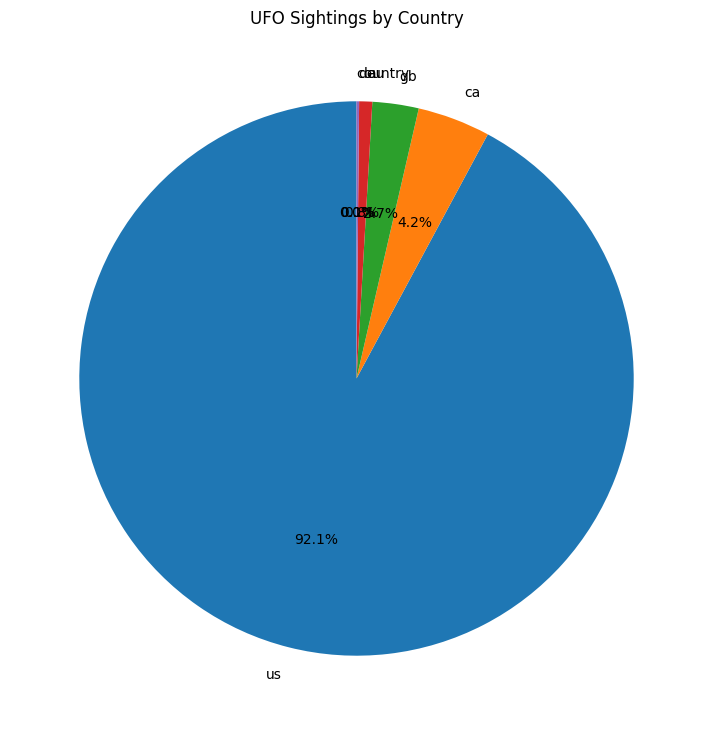

In [9]:
#this is the pie chart. had to import matplot as i had not 



column_names = ['Date', 'city', 'state', 'country', 'shape', 'duration (seconds)', 'duration (hours/min)', 'comments', 'date posted']
df = pd.read_csv(r"C:\Users\Do it ball\Desktop\ufo data\ufos.csv", names=column_names, usecols=range(len(column_names)), on_bad_lines='skip')

countryamount = df['country'].value_counts()


plt.figure(figsize=(9, 9)) 


plt.pie(countryamount, labels=countryamount.index, autopct='%1.1f%%', startangle=90)

plt.title("UFO Sightings by Country")

plt.show()